In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import f_oneway
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder,OrdinalEncoder,StandardScaler
from sklearn.feature_selection import VarianceThreshold
from sklearn.model_selection import RandomizedSearchCV,GroupKFold,cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import Lasso
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import r2_score,mean_squared_error
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings("ignore", category=UserWarning)

## About the dataset:
The FIFA World Cup 2026 Player Performance Dataset is a comprehensive collection of player statistics, match events, and performance metrics gathered throughout the tournament. This dataset provides detailed insights into individual and team performances across all stages of the competition.
## About Attributes:
- player_id: Unique alphanumeric identifier for each player.
- player_name: Full name of the player.
- age: Age of the player at the time of the tournament.
- nationality: The home nation/country of the player.
- team: The national team the player is representing in the tournament.
- jersey_number: The player's kit/jersey number for the match.
- position: Tactical role of the player on the pitch (e.g., Goalkeeper, Defender, Midfielder, Forward).
- height_cm: Player's height measured in centimeters.
- weight_kg: Player's weight measured in kilograms.
- preferred_foot: The dominant foot of the player (Left or Right).

In [2]:
df=pd.read_csv('2P_fifa_world_cup_2026_player_performance.csv')
df.head()

,player_id,player_name,age,nationality,team,jersey_number,position,height_cm,weight_kg,preferred_foot,...,possession_impact,pressure_resistance,creativity_score,consistency_score,clutch_performance_score,total_goals_tournament,total_assists_tournament,total_minutes_tournament,player_of_match_awards,tournament_rating
0,P00055,Rodri Fati,26,Spanish,Spain,3,Goalkeeper,195,75,Left,...,1.1,44.2,55.9,42.0,51.8,0,0,242,0,5.8
1,P00070,Ansu Le Normand,19,Spanish,Spain,18,Midfielder,178,75,Right,...,3.5,38.2,43.7,31.1,52.7,0,3,342,0,5.5
2,P00066,Gavi Ramos,18,Spanish,Spain,14,Midfielder,177,72,Left,...,15.3,99.0,99.0,83.4,54.8,1,1,245,0,8.4
3,P00073,Pedro Cubarsi,20,Spanish,Spain,21,Forward,182,74,Right,...,1.2,19.8,42.3,40.9,78.5,5,3,422,0,6.7
4,P00059,Alvaro Oyarzabal,23,Spanish,Spain,7,Defender,191,81,Left,...,6.2,44.1,33.5,60.0,56.6,0,0,440,0,5.7


## Data Preprocessing

In [3]:
import numpy as np
df.replace('?',np.nan,inplace=True)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54600 entries, 0 to 54599
Data columns (total 75 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   player_id                 54600 non-null  object 
 1   player_name               54600 non-null  object 
 2   age                       54600 non-null  int64  
 3   nationality               54600 non-null  object 
 4   team                      54600 non-null  object 
 5   jersey_number             54600 non-null  int64  
 6   position                  54600 non-null  object 
 7   height_cm                 54600 non-null  int64  
 8   weight_kg                 54600 non-null  int64  
 9   preferred_foot            54600 non-null  object 
 10  club_name                 54600 non-null  object 
 11  market_value_eur          54600 non-null  int64  
 12  match_id                  54600 non-null  object 
 13  match_date                54600 non-null  object 
 14  stadiu

**features available before the prediction was made; causing data leakage:** (Drop these features because they can cause data leakage)
- performance_score
- player_rating
- tournament_rating
- offensive_contribution
- defensive_contribution
- possession_impact
- pressure_resistance
- creativity_score
- consistency_score
- clutch_performance_score


- total_goals_tournament    
- total_assists_tournament  
- total_minutes_tournament
- player_of_match_awards


In [5]:
features = [
    "age",
    "height_cm",
    "weight_kg",
    "position",
    "preferred_foot",
    "market_value_eur",

    "minutes_played",
    "goals_team",
    "goals_opponent",
    "match_result",
    "opponent_team",
    "tournament_stage",

    "goals",
    "assists",
    "shots",
    "shots_on_target",
    "expected_goals_xg",
    "expected_assists_xa",
    "key_passes",
    "offsides",

    "successful_passes",
    "total_passes",
    "pass_accuracy",
    "dribbles_attempted",
    "successful_dribbles",
    "crosses",
    "successful_crosses",

    "tackles",
    "interceptions",
    "clearances",
    "blocks",
    "aerial_duels_won",
    "aerial_duels_lost",
    "recoveries",
    "defensive_actions",

    "fouls_committed",
    "fouls_suffered",
    "yellow_cards",
    "red_cards",

    "saves",
    "save_percentage",
    "punches",
    "clean_sheet",
    "goals_conceded",
    "penalty_saves",

    "distance_covered_km",
    "sprint_distance_km",
    "top_speed_kmh",
    "accelerations",
    "decelerations",
    "stamina_score"
]

X = df[features]
y = df["performance_score"]

**Can we predict how well a player will perform when the model has never seen that player before?**
then use  a GroupShuffleSplit or GroupKFold, grouping by player_id.
bcz this isn't simply a dataset where every row represents a completely independent player.

If you want a testing whether the model generalizes to completely unseen players then dont use train_test_split()
otherwise the model can see the same player's characteristics in both training and testing data (A player appears in multiple matches)

In [6]:
# Use GroupShuffleSplit in case of repeated player ids
from sklearn.model_selection import GroupShuffleSplit
groups = df["player_id"]
gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.30,
    random_state=42
)

train_idx, test_idx = next(
    gss.split(X, y, groups=groups)
)


X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

# Keep player IDs ONLY for checking the groups
train_groups = groups.iloc[train_idx]
test_groups = groups.iloc[test_idx]

In [7]:
# Select numeric, ordinal and nominal columns list
numeric_cols=X_train.select_dtypes(include=['int64','float64']).columns.tolist()
ordinal_cols=['match_result','tournament_stage']
nominal_cols=['position','preferred_foot','opponent_team']

match_result=['L','D','W']
tournament_stage=['Group Stage', 'Round of 32', 'Round of 16', 'Quarter Finals','Semi Finals', 'Third Place Match', 'Final']
categories=[match_result,tournament_stage]

In [8]:
# Apply encoders
preprocessor=ColumnTransformer(
    transformers=
     [('nominal',OneHotEncoder(drop='first',handle_unknown='ignore',sparse_output=False),nominal_cols),
      ('ordinal',OrdinalEncoder(categories=categories,handle_unknown='use_encoded_value',unknown_value=-1),ordinal_cols),
       ('numerical',StandardScaler(),numeric_cols)],
    remainder='passthrough',
    verbose_feature_names_out=False  # Remove transformer prefixes
    )

#  Get pandas dataframe
preprocessor.set_output(transform='pandas')

ColumnTransformer(remainder='passthrough',
                  transformers=[('nominal',
                                 OneHotEncoder(drop='first',
                                               handle_unknown='ignore',
                                               sparse_output=False),
                                 ['position', 'preferred_foot',
                                  'opponent_team']),
                                ('ordinal',
                                 OrdinalEncoder(categories=[['L', 'D', 'W'],
                                                            ['Group Stage',
                                                             'Round of 32',
                                                             'Round of 16',
                                                             'Quarter Finals',
                                                             'Semi Finals',
                                                             'Third Place '
                                                             'Match',
                                                             'Final']],
                                                handle_unknown=...
                                  'expected_goals_xg', 'expected_assists_xa',
                                  'key_passes', 'offsides', 'successful_passes',
                                  'total_passes', 'pass_accuracy',
                                  'dribbles_attempted', 'successful_dribbles',
                                  'crosses', 'successful_crosses', 'tackles',
                                  'interceptions', 'clearances', 'blocks',
                                  'aerial_duels_won', 'aerial_duels_lost',
                                  'recoveries', 'defensive_actions', ...])],
                  verbose_feature_names_out=False)

## Exploratory Analysis

In [13]:
print('**Correlation between numeric predictors and numeric target**')
numeric_data=df.select_dtypes(include=["int64","float64"])
numeric_data.corr()["performance_score"].drop("performance_score").sort_values()

**Correlation between numeric predictors and numeric target**


height_cm                  -0.078225
weight_kg                  -0.046869
age                        -0.038799
penalty_saves              -0.032103
defensive_contribution     -0.014364
goals_opponent             -0.008235
red_cards                  -0.006270
yellow_cards                0.003052
goals_team                  0.008800
clutch_performance_score    0.013340
pressure_resistance         0.066565
consistency_score           0.071934
pass_accuracy               0.074370
market_value_eur            0.076187
clean_sheet                 0.079622
creativity_score            0.086902
total_goals_tournament      0.090961
total_assists_tournament    0.097004
punches                     0.103741
jersey_number               0.110398
successful_crosses          0.114180
goals_conceded              0.117695
offsides                    0.128127
offensive_contribution      0.136697
saves                       0.141677
player_of_match_awards      0.144944
save_percentage             0.157542
s

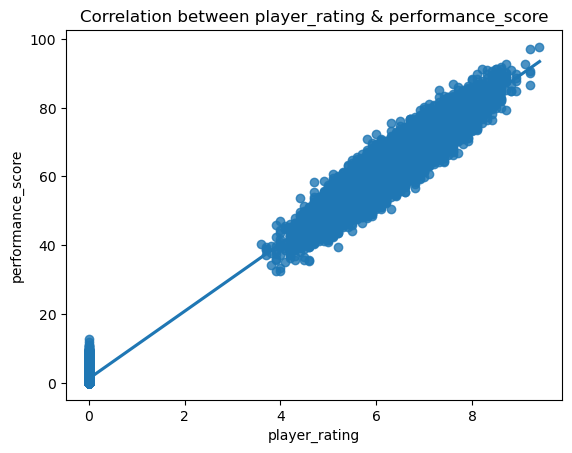

In [16]:
sns.regplot(x="player_rating",y="performance_score",data=df)
plt.title("Correlation between player_rating & performance_score")
plt.show()

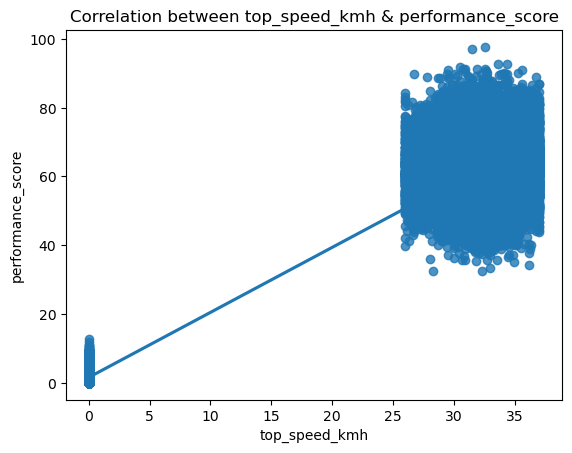

In [23]:
sns.regplot(x="top_speed_kmh",y="performance_score",data=df)
plt.title("Correlation between top_speed_kmh & performance_score")
plt.show()

In [11]:
print('**Correlation between categoric predictors and numeric target**')
categoric_data=df.select_dtypes(include=["object"])
result=[]
for column in categoric_data.columns:
    group=df.groupby(column)["performance_score"].apply(list)
    f_static, p_value=f_oneway(*group)
    result.append({"column":column,"p_value":p_value})
ANOVA=pd.DataFrame(result).sort_values(by="p_value",ascending=False)
print(ANOVA)

**Correlation between categoric predictors and numeric target**
              column        p_value
7           match_id   1.000000e+00
8         match_date   1.000000e+00
11     opponent_team   1.000000e+00
3               team   9.999891e-01
2        nationality   9.999891e-01
9            stadium   9.999842e-01
10              city   9.999842e-01
12  tournament_stage   9.575981e-01
5     preferred_foot   4.926610e-01
13      match_result   8.400443e-03
6          club_name   1.280539e-18
1        player_name  1.085819e-189
0          player_id  2.447345e-190
4           position   0.000000e+00


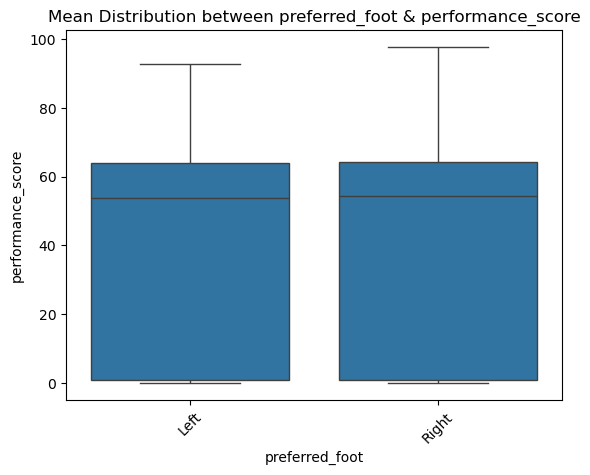

In [10]:
sns.boxplot(x="preferred_foot",y="performance_score",data=df)
plt.xticks(rotation=45)
plt.title("Mean Distribution between preferred_foot & performance_score")
plt.show()

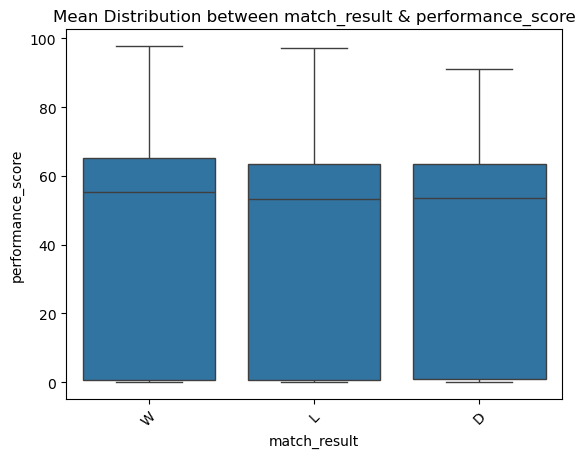

In [11]:
sns.boxplot(x="match_result",y="performance_score",data=df)
plt.xticks(rotation=45)
plt.title("Mean Distribution between match_result & performance_score")
plt.show()

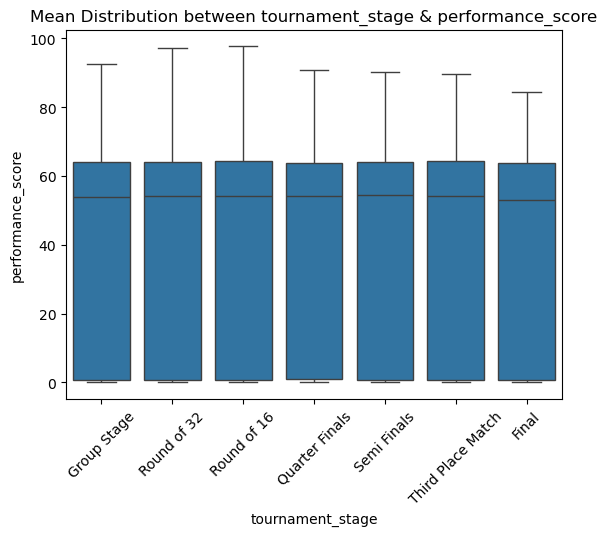

In [13]:
sns.boxplot(x="tournament_stage",y="performance_score",data=df)
plt.xticks(rotation=45)
plt.title("Mean Distribution between tournament_stage & performance_score")
plt.show()

## Models

In [10]:
# Find best hyperparameters for Lasso
full_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('variance_selector', VarianceThreshold(threshold=0.1)),
    ('model',Lasso(max_iter=10000))
])
# Configure variance selector output as pandas
full_pipeline.set_output(transform='pandas')
parameters={'model__alpha':[0.1,0.2,0.3]}

cv = GroupKFold(n_splits=3)
search = RandomizedSearchCV(
    estimator=full_pipeline,
    param_distributions=parameters,
    n_iter=3,             # tests only 3 parameter combinations.
    cv=cv,
    scoring='neg_mean_squared_error',
    random_state=42,
    n_jobs=2,
    verbose=1
)

search.fit(X_train,y_train,groups=train_groups)
print('best cv score:',search.best_score_)
print('best hyperparametrs:',search.best_params_)

Fitting 3 folds for each of 3 candidates, totalling 9 fits
best cv score: -38.85824944716534
best hyperparametrs: {'model__alpha': 0.1}


In [11]:
# Lasso
model=search.best_estimator_
y_pred=model.predict(X_test)
print('y_pred:',y_pred[:5])
print('r2_score:',r2_score(y_test,y_pred))
print('mean_squared_error',mean_squared_error(y_test,y_pred))

y_pred: [57.12965829 76.34927888 59.85641212 60.19995497 60.68303799]
r2_score: 0.9576770113584738
mean_squared_error 40.27286343344578


In [13]:
# Find best hyperparameters for RandomForestRegressor
full_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('variance_selector', VarianceThreshold(threshold=0.1)),
    ('model',RandomForestRegressor(random_state=42,n_jobs=1))
])
# Configure variance selector output as pandas
full_pipeline.set_output(transform='pandas')
parameters={'model__n_estimators':[20,50,100]}

cv = GroupKFold(n_splits=3)
search = RandomizedSearchCV(
    estimator=full_pipeline,
    param_distributions=parameters,
    n_iter=3,             # tests only 3 parameter combinations.
    cv=cv,
    scoring='neg_mean_squared_error',
    random_state=42,
    n_jobs=2,
    verbose=1
)
search.fit(X_train,y_train,groups=train_groups)  # GroupKFold requires the groups argument
print('best cv score:',search.best_score_)
print('best hyperparameters:',search.best_params_)

Fitting 3 folds for each of 3 candidates, totalling 9 fits
best cv score: -30.70344393839048
best hyperparameters: {'model__n_estimators': 100}


In [14]:
# RandomForestRegressor
model=search.best_estimator_
y_pred=model.predict(X_test)
print('y_pred:',y_pred[:5])
print('r2_score:',r2_score(y_test,y_pred))
print('mean_squared_error:',mean_squared_error(y_test,y_pred))

y_pred: [60.117 71.593 64.005 66.654 61.494]
r2_score: 0.9667645814924207
mean_squared_error: 31.62549511911997


In [15]:
# Find best hyperparameters for XGBRegressor

full_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('variance_selector', VarianceThreshold(threshold=0.1)),
    ('model',XGBRegressor(n_jobs=1))
])
# Configure variance selector output as pandas
full_pipeline.set_output(transform='pandas')

parameters={'model__n_estimators':[20,50,100]}

cv = GroupKFold(n_splits=3)
search = RandomizedSearchCV(
    estimator=full_pipeline,
    param_distributions=parameters,
    n_iter=3,             # tests only 3 parameter combinations.
    cv=cv,
    scoring='neg_mean_squared_error',
    random_state=42,
    n_jobs=2,
    verbose=1
)
search.fit(X_train,y_train,groups=train_groups)  # GroupKFold requires the groups argument
print('best cv score:',search.best_score_)
print('best hyperparameters:',search.best_params_)

Fitting 3 folds for each of 3 candidates, totalling 9 fits
best cv score: -30.257475120765008
best hyperparameters: {'model__n_estimators': 20}


In [16]:
# FINAL XGBREGRESSOR
model=search.best_estimator_
y_pred = model.predict(X_test)
print('y_pred:',y_pred[:5])
print('r2_score:',r2_score(y_test,y_pred))
print('mean_squared_error',mean_squared_error(y_test,y_pred))

y_pred: [59.962074 72.17474  63.15184  66.459915 62.612953]
r2_score: 0.9670890410070976
mean_squared_error 31.31675242056108


Text(0.5, 0, 'mean_squared_error')

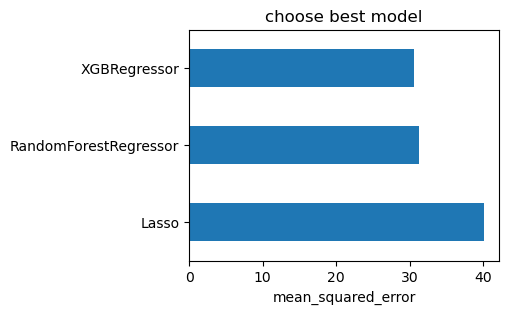

In [29]:
mean_squared_error=[40.145538547366115,31.199714192810465,30.625452665986828]
models=['Lasso','RandomForestRegressor','XGBRegressor']
pd.Series(mean_squared_error,index=models).plot(kind='barh',figsize=(4,3))
plt.title('choose best model')
plt.xlabel('mean_squared_error')